# Firma de una clase

Etapa 2 de `plan_python.md`. Muestra la forma de onda y el histograma de todas las tomas de una carpeta. La clase es el nombre de esa carpeta.

Lee los `.raw` de `carpeta/outputs/`, el PCM que escribió `2_raw_carpeta_process_1.py`. No vuelve a convertir los WAV.

Para cambiar de clase, editá `CARPETA` y volvé a correr las celdas desde ahí. Los valores que andan ahora son `grabacion/parche`, `grabacion/anillo` y `grabacion/ambiente`.

El kernel tiene que ser el Python de `tinyml`: `C:\Users\angel\miniconda3\envs\tinyml\python.exe`. `ipykernel` solo abre esta notebook en la PC. No viaja al ESP32-P4.

Desde `pruebas_py`, con el entorno activo, si el kernel todavía no arranca:

```powershell
python -m pip install -r requirements.txt
```


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FRECUENCIA_HZ = 16000
#CARPETA = "grabacion/parche"
CARPETA = "grabacion/anillo"


def resolver_carpeta(texto):
    ruta = Path(texto)
    if ruta.is_dir():
        return ruta
    desde_pruebas = Path("pruebas_py") / texto
    if desde_pruebas.is_dir():
        return desde_pruebas
    raise FileNotFoundError(texto)


carpeta = resolver_carpeta(CARPETA)
clase = carpeta.name
raws = sorted((carpeta / "outputs").glob("*.raw"))
if not raws:
    raise FileNotFoundError("no hay .raw en %s" % (carpeta / "outputs"))

tomas = []
for ruta in raws:
    pcm = np.fromfile(ruta, dtype="<i2")
    tomas.append({"nombre": ruta.stem, "pcm": pcm})

print("clase:", clase)
print("carpeta:", carpeta)
print("tomas:", len(tomas))
print("muestras:", sum(t["pcm"].size for t in tomas))


clase: anillo
carpeta: grabacion\anillo
tomas: 30
muestras: 787120


## Histograma de la clase

Junta todas las muestras int16 de la carpeta. El pico cerca de 0 es el tramo en que el golpe todavía no suena, o el ambiente de baja amplitud. Las colas son las muestras fuertes del evento.


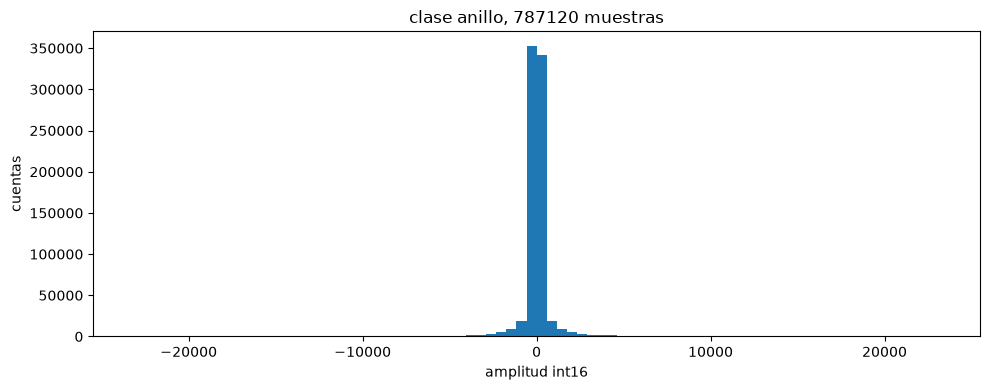

In [16]:
todo = np.concatenate([t["pcm"] for t in tomas])

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(todo, bins=80)
ax.set_title("clase %s, %d muestras" % (clase, todo.size))
ax.set_xlabel("amplitud int16")
ax.set_ylabel("cuentas")
fig.tight_layout()
plt.show()


## Cada toma

A la izquierda, la forma de onda completa. A la derecha, el histograma de esa toma. El alto de la figura crece con la cantidad de archivos para poder recorrerlos en la misma vista.


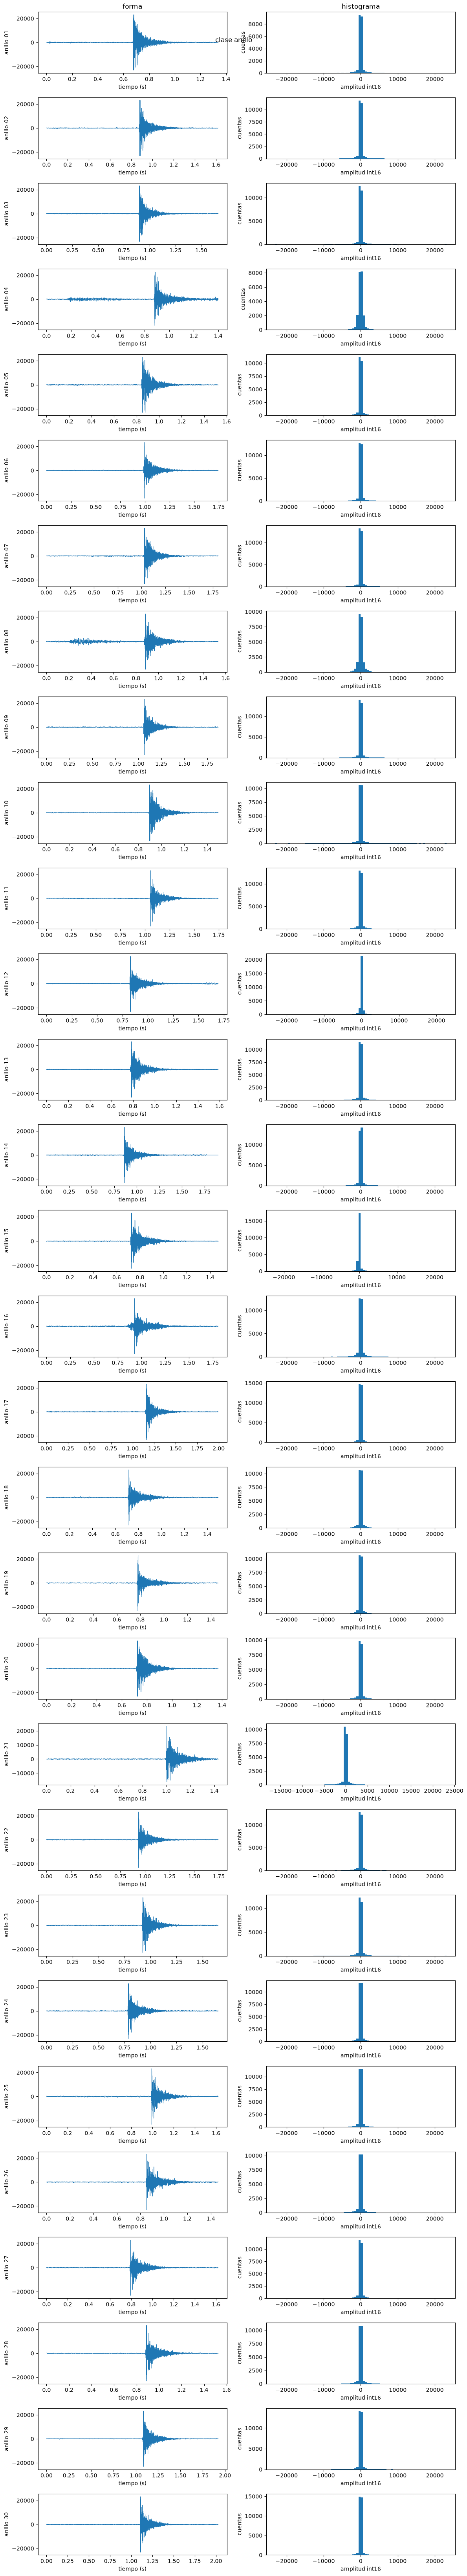

In [17]:
filas = len(tomas)
fig, axes = plt.subplots(filas, 2, figsize=(12, 2.2 * filas), squeeze=False)

for i, toma in enumerate(tomas):
    pcm = toma["pcm"]
    tiempo_s = np.arange(pcm.size) / FRECUENCIA_HZ
    axes[i, 0].plot(tiempo_s, pcm, linewidth=0.6)
    axes[i, 0].set_ylabel(toma["nombre"])
    axes[i, 0].set_xlabel("tiempo (s)")
    axes[i, 1].hist(pcm, bins=80)
    axes[i, 1].set_xlabel("amplitud int16")
    axes[i, 1].set_ylabel("cuentas")

axes[0, 0].set_title("forma")
axes[0, 1].set_title("histograma")
fig.suptitle("clase %s" % clase)
fig.tight_layout()
plt.show()


## Avisos

Estas cuentas comparan cada toma con las otras de la misma carpeta. Si salta un aviso, el archivo queda fuera de entrenamiento, de validación y de prueba. El conjunto de prueba tiene que ser tomas normales que no se usaron para elegir el modelo. Una grabación con otro sonido, o con el golpe casi ausente, contesta otra pregunta y no se usa para esa métrica.

La celda imprime `Remove-Item` para PowerShell y `rm` para Linux, el WAV y el `.raw`. No ejecuta esos comandos.

- Ruido antes del golpe: el RMS previo al ataque tiene z robusto mayor que 6.
- Otro sonido después: tras 100 ms por debajo de RMS 80, el nivel vuelve a pasar el 15 % del pico.
- Golpe débil: el pico es menor que el 25 % de la mediana y menor que la mitad del pico siguiente. Así no marca un ambiente apenas más bajo que los demás.


In [18]:
import warnings

warnings.simplefilter("always", UserWarning)

PASO = int(0.020 * FRECUENCIA_HZ)
Z_RUIDO_ANTES = 6.0
RMS_CAIDA = 80.0
VENTANAS_CAIDA = 5
FRACCION_REBOTE = 0.15
FRACCION_PICO = 0.25
FRACCION_SIGUIENTE = 0.5


def rms_bloque(x):
    if x.size == 0:
        return 0.0
    return float(np.sqrt(np.mean(x.astype(np.float64) ** 2)))


def envolvente(x):
    n = 1 + (x.size - 1) // PASO
    salida = np.empty(n)
    for i in range(n):
        salida[i] = rms_bloque(x[i * PASO : (i + 1) * PASO])
    return salida


def z_robusto(valores):
    arr = np.asarray(valores, dtype=np.float64)
    med = np.median(arr)
    mad = np.median(np.abs(arr - med))
    escala = 1.4826 * mad
    if escala == 0.0:
        escala = 1.0
    return (arr - med) / escala


filas = []
for toma in tomas:
    x = toma["pcm"]
    env = envolvente(x)
    pico_i = int(np.argmax(env))
    inicio = pico_i
    while inicio > 0 and env[inicio] > 0.20 * env[pico_i]:
        inicio -= 1
    racha = 0
    caido = None
    for i in range(pico_i, env.size):
        if env[i] < RMS_CAIDA:
            racha += 1
            if racha >= VENTANAS_CAIDA:
                caido = i
                break
        else:
            racha = 0
    if caido is None:
        rebote = 0.0
    else:
        rebote = float(np.max(env[caido:]))
    filas.append(
        {
            "nombre": toma["nombre"],
            "rms_antes": rms_bloque(x[: inicio * PASO]),
            "pico": float(env[pico_i]),
            "rebote": rebote,
        }
    )

z_antes = z_robusto([f["rms_antes"] for f in filas])
mediana_pico = float(np.median([f["pico"] for f in filas]))
picos_ordenados = sorted(f["pico"] for f in filas)
pico_siguiente = picos_ordenados[1] if len(picos_ordenados) > 1 else picos_ordenados[0]
avisos = []
rechazadas = []
for f, z in zip(filas, z_antes):
    motivos = 0
    if z > Z_RUIDO_ANTES:
        avisos.append(
            "%s: ruido antes del golpe (rms %.0f, z %.1f)"
            % (f["nombre"], f["rms_antes"], z)
        )
        motivos += 1
    if f["pico"] > 0.0 and f["rebote"] > FRACCION_REBOTE * f["pico"]:
        avisos.append(
            "%s: otro sonido despues del golpe (rebote %.0f, pico %.0f)"
            % (f["nombre"], f["rebote"], f["pico"])
        )
        motivos += 1
    if (
        f["pico"] < FRACCION_PICO * mediana_pico
        and f["pico"] < FRACCION_SIGUIENTE * pico_siguiente
    ):
        avisos.append(
            "%s: golpe mucho mas debil que la clase (pico %.0f, mediana %.0f)"
            % (f["nombre"], f["pico"], mediana_pico)
        )
        motivos += 1
    if motivos:
        rechazadas.append(f["nombre"])

print("clase:", clase)
print("mediana del pico:", round(mediana_pico, 1))
if not avisos:
    print("sin avisos")
else:
    print("avisos:", len(avisos))
    for linea in avisos:
        warnings.warn(linea, UserWarning)
    print("se recomienda borrar las muestras:")
    print("PowerShell:")
    for nombre in rechazadas:
        print("Remove-Item", carpeta / (nombre + ".wav"))
        print("Remove-Item", carpeta / "outputs" / (nombre + ".raw"))
    print("Linux:")
    for nombre in rechazadas:
        print("rm", (carpeta / (nombre + ".wav")).as_posix())
        print("rm", (carpeta / "outputs" / (nombre + ".raw")).as_posix())


clase: anillo
mediana del pico: 6204.7
avisos: 2
se recomienda borrar las muestras:
PowerShell:
Remove-Item grabacion\anillo\anillo-04.wav
Remove-Item grabacion\anillo\outputs\anillo-04.raw
Remove-Item grabacion\anillo\anillo-08.wav
Remove-Item grabacion\anillo\outputs\anillo-08.raw
Linux:
rm grabacion/anillo/anillo-04.wav
rm grabacion/anillo/outputs/anillo-04.raw
rm grabacion/anillo/anillo-08.wav
rm grabacion/anillo/outputs/anillo-08.raw


C:\Users\angel\AppData\Local\Temp\ipykernel_11792\3118238927.py:108: UserWarning: anillo-04: ruido antes del golpe (rms 447, z 11.6)
  warnings.warn(linea, UserWarning)
C:\Users\angel\AppData\Local\Temp\ipykernel_11792\3118238927.py:108: UserWarning: anillo-08: ruido antes del golpe (rms 589, z 17.2)
  warnings.warn(linea, UserWarning)
